# Milestone 2: Model Evaluation
**FEMA Individuals & Households Program (IHP) registrations, Hurricane Ian (DR-4673), Lee County, FL**

**Team FEMA:** Anthony Stoneking, Daniel Ortiz, Nandor Laar
**Course:** CAI 4105 Machine Learning, Fall 2026 · **Owner:** Anthony

## Project Overview
The modeling notebook (`notebooks/modeling/01_model_comparison.ipynb`) compared ten algorithms and chose **gradient boosting** for both tiers.
This notebook takes that chosen model and answers three questions for Section 5 of the report:

1. **How good is it?** The full set of metrics for the chosen model on the validation rows (Section 5.1).
2. **What does it rely on?** Permutation importance: which inputs the model actually uses (Section 5.2, and the "Be explainable" row in Section 2).
3. **Does it hold up over time?** A temporal check: train on the earlier applications, score the later ones (Section 5.5).
4. **Is Tier 2 leaning on a leaky column?** Refit Tier 2 without `currentLocation` (Section 5.5).

**The final test set is never scored here.** `RUN_FINAL_TEST` stays `False`; every number below comes from training or validation rows.

---
# Part 1: Setup and Data Preparation

## Import Required Libraries

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve)
from sklearn.inspection import permutation_importance
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42        # same seed as the modeling notebook, so the split is identical
REPORT_SPLIT = "val"     # this notebook only ever reports on validation rows
RUN_FINAL_TEST = False   # team rule: never score the final test set here
assert REPORT_SPLIT == "val" and not RUN_FINAL_TEST, "This notebook must not touch the test set."
FAIRNESS_LIMIT = 0.05    # Milestone 1 target: no group more than 5 percentage points above the overall error rate
MIN_GROUP_ROWS = 100     # groups smaller than this are shown but not judged

## Chart style
Same colors as the modeling notebook.

In [2]:
BLUE = "#2a78d6"    # Tier 1 / main series
AQUA = "#1baf7a"    # Tier 2
ORANGE = "#eb6834"  # over the limit / not eligible
GRAY = "#898781"
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
TIER_COLORS = {"application": BLUE, "inspection": AQUA}
TIER_NAMES = {"application": "Tier 1 (application)", "inspection": "Tier 2 (inspection)"}

# Find the project folder, so figures land in reports/figures no matter where the notebook is run from
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
FIG_DIR = ROOT / "reports" / "figures"

plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"], "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.edgecolor": GRID, "axes.grid": True, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "text.color": INK, "legend.frameon": False,
    "lines.linewidth": 2,
})


def save_fig(name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    plt.savefig(FIG_DIR / f"m2_fair_{name}.png")


def tick_labels(index):
    # matplotlib reads "$" as the start of a math formula, so income labels need it escaped
    return [str(v).replace("$", r"\$") for v in index]


LABEL_BOX = dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9)   # keeps value labels readable over lines

## Load the data

In [3]:
CSV_NAME = "ihp_dr4673_lee.csv"
CSV_CANDIDATES = [Path(CSV_NAME), ROOT / "data" / "raw" / CSV_NAME]


PARQUET_CANDIDATES = [p.with_suffix(".parquet") for p in CSV_CANDIDATES]  # cache written by src/data/fetch_fema.py


def load_data():
    for path in CSV_CANDIDATES:
        if path.exists():
            return pd.read_csv(path, low_memory=False)
    for path in PARQUET_CANDIDATES:
        if path.exists():
            return pd.read_parquet(path)
    raise FileNotFoundError(f"Put {CSV_NAME} in data/raw/ or in the same folder as this notebook.")


raw = load_data()
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")

194,482 rows x 100 columns


## Same features, cleaning, split, and preprocessing as the modeling notebook
The next four cells are copied from `01_model_comparison.ipynb` (via the fairness notebook) without changes.
They must stay identical: the same seed and the same steps give the same training, validation, and test rows, so the fairness results describe the same model the team selected.

In [4]:
TARGET = "ihpEligible"

# Tier 1: known at registration (self-reported)
APPLICATION_FEATURES = [
    "appliedDate", "applicantAge", "householdComposition",
    "occupantsUnderTwo", "occupants2to5", "occupants6to18", "occupants19to64", "occupants65andOver",
    "grossIncome", "ownRent", "primaryResidence", "residenceType",
    "homeOwnersInsurance", "floodInsurance", "registrationMethod",
    "damagedZipCode", "censusGeoid",
    "homeDamage", "autoDamage", "reportedDamage", "selfAssessmentInformation",
    "emergencyNeeds", "foodNeed", "shelterNeed", "accessFunctionalNeeds",
]
# Tier 2: only known after a FEMA inspection or verification step
INSPECTION_FEATURES = [
    "inspnIssued", "inspnReturned", "rpfvl", "ppfvl",
    "floodDamage", "floodDamageAmount", "waterLevel", "highWaterLocation",
    "destroyed", "renterDamageLevel", "verifiedOwnership", "verifiedOccupancy",
    "habitabilityRepairsRequired", "currentLocation",
]
TIERS = {"application": APPLICATION_FEATURES, "inspection": APPLICATION_FEATURES + INSPECTION_FEATURES}

# ineligibleReason is a RESULT of FEMA's decision. It is never a model input.
# This notebook only uses it afterwards, to describe who the model got wrong (Part 3).
assert "ineligibleReason" not in TIERS["inspection"]

In [5]:
LANDFALL = pd.Timestamp("2022-09-28")
AGE_ORDER = {"<19": 0, "19-34": 1, "35-49": 2, "50-64": 3, "65+": 4}
COUNT_ORDER = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, ">5": 6}
COUNT_COLS = ["householdComposition", "occupantsUnderTwo", "occupants2to5",
              "occupants6to18", "occupants19to64", "occupants65andOver"]
CATEGORICAL_COLS = ["grossIncome", "ownRent", "residenceType", "registrationMethod", "currentLocation",
                    "selfAssessmentInformation", "damagedZipCode", "censusGeoid",
                    "highWaterLocation", "renterDamageLevel"]


def clean(raw, tier):
    df = raw[[TARGET] + TIERS[tier]].copy()
    df[TARGET] = df[TARGET].astype(int)

    applied = pd.to_datetime(df.pop("appliedDate"), utc=True).dt.tz_localize(None)
    df["daysSinceLandfall"] = (applied - LANDFALL).dt.days

    df["applicantAge"] = df["applicantAge"].map(AGE_ORDER)
    for c in COUNT_COLS:
        df[c] = df[c].astype(str).map(COUNT_ORDER)

    for c in df.columns:
        values = df[c].dropna()
        if c != TARGET and len(values) and values.map(type).eq(bool).all():
            df[c] = df[c].map({True: 1.0, False: 0.0})

    for c in CATEGORICAL_COLS:
        if c in df.columns:
            df[c] = df[c].map(lambda v: v if pd.isna(v) else str(v)).astype(object)
    return df


tables = {tier: clean(raw, tier) for tier in TIERS}

In [6]:
idx_trainval, idx_test = train_test_split(
    tables["application"].index, test_size=0.20, stratify=tables["application"][TARGET], random_state=RANDOM_STATE)
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=0.25, stratify=tables["application"].loc[idx_trainval, TARGET], random_state=RANDOM_STATE)
SPLIT_INDEX = {"train": idx_train, "val": idx_val, "test": idx_test}

DATA = {}
for tier, df in tables.items():
    X, y = df.drop(columns=TARGET), df[TARGET]
    DATA[tier] = {name: (X.loc[idx], y.loc[idx]) for name, idx in SPLIT_INDEX.items()}

pd.DataFrame({
    name: {"rows": len(idx), "share eligible": tables["application"].loc[idx, TARGET].mean().round(3)}
    for name, idx in SPLIT_INDEX.items()
}).T

,rows,share eligible
train,116688.0,0.507
val,38897.0,0.507
test,38897.0,0.507


In [7]:
PLACE_COLS = ["damagedZipCode", "censusGeoid"]
SKEWED_COLS = ["rpfvl", "ppfvl", "floodDamageAmount", "waterLevel"]


class FrequencyEncoder(BaseEstimator, TransformerMixin):
    # Replace each code with the number of training rows that have it (unseen codes get 0).

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.counts_ = {c: X[c].value_counts() for c in X.columns}
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        return np.column_stack([X[c].map(self.counts_[c]).fillna(0).astype(float) for c in X.columns])

    def get_feature_names_out(self, input_features=None):
        return np.asarray(list(self.counts_), dtype=object)


def make_preprocessor(X):
    place = [c for c in PLACE_COLS if c in X.columns]
    skewed = [c for c in SKEWED_COLS if c in X.columns]
    categorical = [c for c in X.columns if X[c].dtype == object and c not in place]
    numeric = [c for c in X.columns if c not in place + skewed + categorical]
    return ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), numeric),
        ("skewed", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), skewed),
        ("place", make_pipeline(FrequencyEncoder(), FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), place),
        ("categorical", make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"),
                                      OneHotEncoder(handle_unknown="ignore", sparse_output=False)), categorical),
    ])

## Refit the chosen model
The modeling notebook selected **gradient boosting** for both tiers and found its best settings with a 5-fold grid search.
We do not repeat the search here. We refit the model once per tier with those winning settings, on the same training rows.

The check table compares our validation AUC with the one reported in the modeling notebook. They should agree to about two decimals. If they do not, the two notebooks are not scoring the same model and the results below should not be used.

In [8]:
# Best settings and validation AUC, copied from the "Gradient boosting" results table in 01_model_comparison.ipynb
BEST_SETTINGS = {
    "application": {"learning_rate": 0.1, "max_leaf_nodes": 63},
    "inspection": {"learning_rate": 0.05, "max_leaf_nodes": 63},
}
MODELING_NOTEBOOK_VAL_AUC = {"application": 0.880, "inspection": 0.938}

MODELS = {}
check = []
for tier in TIERS:
    X_tr, y_tr = DATA[tier]["train"]
    X_va, y_va = DATA[tier]["val"]
    model = Pipeline([
        ("prep", make_preprocessor(X_tr)),
        ("model", HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE,
                                                 **BEST_SETTINGS[tier])),
    ]).fit(X_tr, y_tr)
    MODELS[tier] = model
    auc = roc_auc_score(y_va, model.predict_proba(X_va)[:, 1])
    check.append({"tier": TIER_NAMES[tier], "validation AUC here": round(auc, 3),
                  "modeling notebook": MODELING_NOTEBOOK_VAL_AUC[tier],
                  "difference": round(auc - MODELING_NOTEBOOK_VAL_AUC[tier], 3)})

pd.DataFrame(check).set_index("tier")

,validation AUC here,modeling notebook,difference
tier,,,
Tier 1 (application),0.883,0.880,0.003
Tier 2 (inspection),0.939,0.938,0.001


---
# Part 2: Performance of the Chosen Model (Section 5.1)

AUC ranks applicants and ignores the cut-off. The other four metrics use the default cut-off of 0.5: predicted eligible if the model's probability is at least 0.5.
- **Precision**: of the households the model calls eligible, the share that really received aid.
- **Recall**: of the households that really received aid, the share the model found. One minus recall is the "missed eligible" rate.
- **Train AUC vs validation AUC**: a large gap would mean the model memorised the training rows.

In [9]:
def score(model, X, y, cut=0.5):
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= cut).astype(int)
    return {"AUC": roc_auc_score(y, prob), "accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred), "recall": recall_score(y, pred), "F1": f1_score(y, pred)}


rows, CONFUSION = [], {}
for tier in TIERS:
    model = MODELS[tier]
    X_tr, y_tr = DATA[tier]["train"]
    X_va, y_va = DATA[tier]["val"]
    val = score(model, X_va, y_va)
    rows.append({"tier": TIER_NAMES[tier], **{k: round(v, 3) for k, v in val.items()},
                 "train AUC": round(roc_auc_score(y_tr, model.predict_proba(X_tr)[:, 1]), 3)})
    CONFUSION[tier] = confusion_matrix(y_va, (model.predict_proba(X_va)[:, 1] >= 0.5).astype(int))

METRICS = pd.DataFrame(rows).set_index("tier")
METRICS["train-val gap"] = (METRICS["train AUC"] - METRICS["AUC"]).round(3)
METRICS

,AUC,accuracy,precision,recall,F1,train AUC,train-val gap
tier,,,,,,,
Tier 1 (application),0.883,0.812,0.779,0.877,0.825,0.900,0.017
Tier 2 (inspection),0.939,0.870,0.820,0.953,0.882,0.949,0.010


## Confusion matrices (validation rows, cut-off 0.5)
Rows are what really happened; columns are what the model predicted.

In [10]:
for tier in TIERS:
    cm = CONFUSION[tier]
    table = pd.DataFrame(cm, index=["really not eligible", "really eligible"],
                         columns=["predicted not eligible", "predicted eligible"])
    print(TIER_NAMES[tier])
    display(table)
    tn, fp, fn, tp = cm.ravel()
    print(f"  missed eligible: {fn:,} of {fn + tp:,} ({fn / (fn + tp):.1%})"
          f"   wrongly eligible: {fp:,} of {fp + tn:,} ({fp / (fp + tn):.1%})\n")

Tier 1 (application)


,predicted not eligible,predicted eligible
really not eligible,14261,4906
really eligible,2417,17313


  missed eligible: 2,417 of 19,730 (12.3%)   wrongly eligible: 4,906 of 19,167 (25.6%)

Tier 2 (inspection)


,predicted not eligible,predicted eligible
really not eligible,15053,4114
really eligible,932,18798


  missed eligible: 932 of 19,730 (4.7%)   wrongly eligible: 4,114 of 19,167 (21.5%)



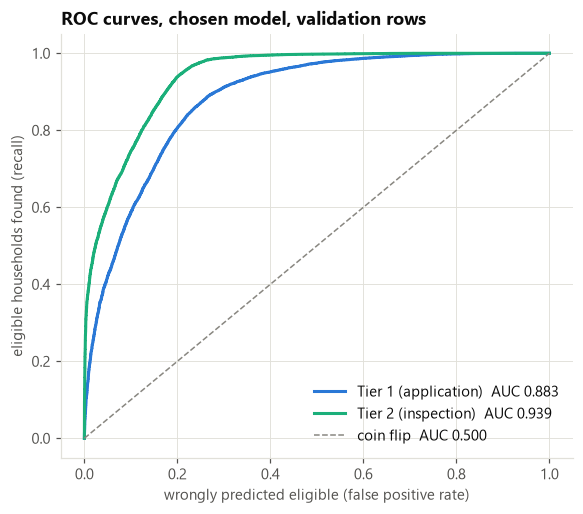

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
for tier in TIERS:
    X_va, y_va = DATA[tier]["val"]
    fpr, tpr, _ = roc_curve(y_va, MODELS[tier].predict_proba(X_va)[:, 1])
    ax.plot(fpr, tpr, color=TIER_COLORS[tier], lw=2,
            label=f"{TIER_NAMES[tier]}  AUC {METRICS.loc[TIER_NAMES[tier], 'AUC']:.3f}")
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1, label="coin flip  AUC 0.500")
ax.set(xlabel="wrongly predicted eligible (false positive rate)", ylabel="eligible households found (recall)",
       title="ROC curves, chosen model, validation rows")
ax.legend(loc="lower right", frameon=False)
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / "m2_eval_roc_curves.png")
plt.show()

---
# Part 3: What the Model Relies On (Section 5.2)

**Permutation importance.** Take one input column in the validation rows, shuffle it so it no longer lines up with the right applicant, and score the model again.
The drop in AUC is that column's importance: a big drop means the model leans on it; no drop means the model could do without it.
We shuffle each column 5 times and report the average drop. We shuffle the raw columns (before encoding), so each bar is one thing an applicant or inspector actually reports.

Importance is not cause. A column can matter because FEMA's own rules use it, not because it explains who deserves aid.

In [12]:
IMPORTANCE = {}
for tier in TIERS:
    X_va, y_va = DATA[tier]["val"]
    result = permutation_importance(MODELS[tier], X_va, y_va, scoring="roc_auc", n_repeats=5,
                                    random_state=RANDOM_STATE, n_jobs=-1)
    IMPORTANCE[tier] = (pd.DataFrame({"AUC drop": result.importances_mean, "spread (sd)": result.importances_std},
                                     index=X_va.columns)
                        .sort_values("AUC drop", ascending=False))

for tier in TIERS:
    print(TIER_NAMES[tier])
    display(IMPORTANCE[tier].head(10).round(4))

# Section 5.2 quotes these two low-importance inputs, so show them too
for tier in TIERS:
    print(TIER_NAMES[tier], "- age and income:")
    display(IMPORTANCE[tier].loc[["applicantAge", "grossIncome"]].round(4))

Tier 1 (application)


,AUC drop,spread (sd)
emergencyNeeds,0.1484,0.0008
primaryResidence,0.0864,0.0013
homeOwnersInsurance,0.0551,0.0002
selfAssessmentInformation,0.0530,0.0010
daysSinceLandfall,0.0388,0.0009
registrationMethod,0.0152,0.0003
householdComposition,0.0118,0.0001
damagedZipCode,0.0102,0.0005
homeDamage,0.0101,0.0004
ownRent,0.0088,0.0004


Tier 2 (inspection)


,AUC drop,spread (sd)
emergencyNeeds,0.1156,0.0007
currentLocation,0.0645,0.0011
habitabilityRepairsRequired,0.0430,0.0007
homeOwnersInsurance,0.0388,0.0003
primaryResidence,0.0347,0.0009
daysSinceLandfall,0.0317,0.0005
verifiedOccupancy,0.0246,0.0007
selfAssessmentInformation,0.0180,0.0003
ppfvl,0.0087,0.0003
rpfvl,0.0064,0.0004


Tier 1 (application) - age and income:


,AUC drop,spread (sd)
applicantAge,0.0053,0.0003
grossIncome,0.0048,0.0003


Tier 2 (inspection) - age and income:


,AUC drop,spread (sd)
applicantAge,0.0013,0.0001
grossIncome,0.0019,0.0002


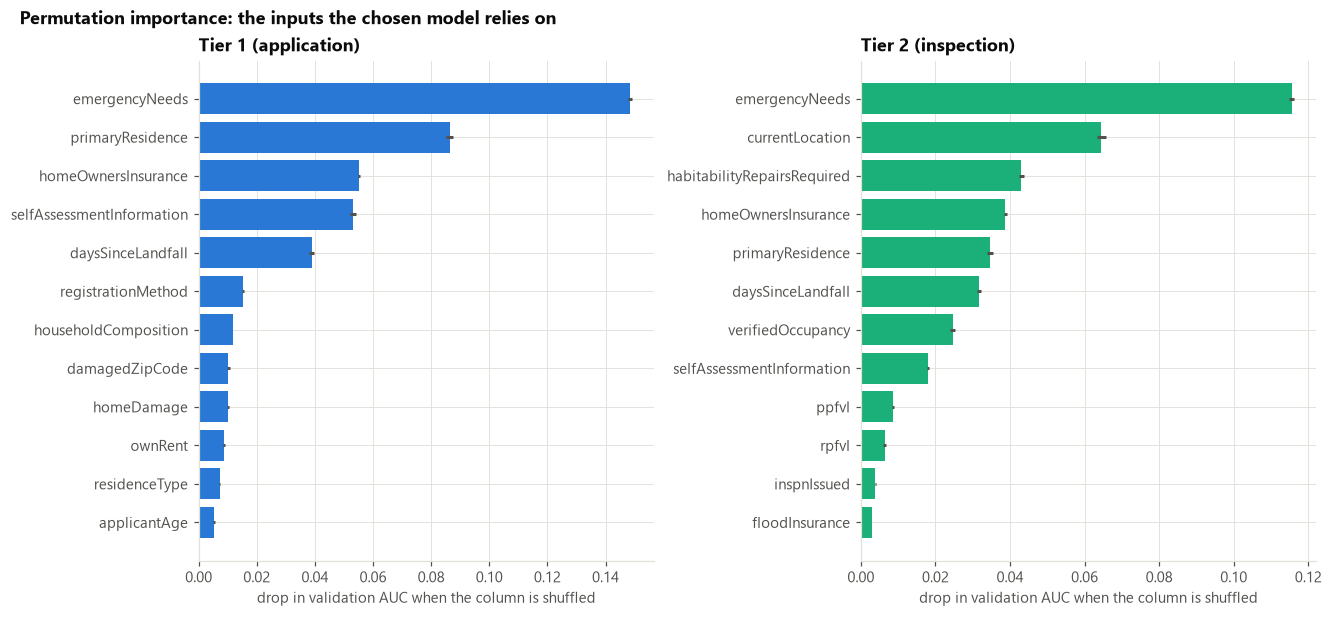

In [13]:
TOP_N = 12
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), layout="constrained")
for ax, tier in zip(axes, TIERS):
    top = IMPORTANCE[tier].head(TOP_N)[::-1]
    ax.barh(top.index, top["AUC drop"], xerr=top["spread (sd)"], color=TIER_COLORS[tier], ecolor=INK_SOFT)
    ax.set(title=TIER_NAMES[tier], xlabel="drop in validation AUC when the column is shuffled")
fig.suptitle("Permutation importance: the inputs the chosen model relies on", fontweight="bold", x=0.01, ha="left")
fig.savefig(FIG_DIR / "m2_eval_permutation_importance.png")
plt.show()

---
# Part 4: Does It Hold Up Over Time? (Section 5.5)

The random split mixes early and late applications, so the model has seen applicants from every week.
FEMA would use the model on **new** applications, after training on older ones. To imitate that, we use only the training and validation rows (the test rows stay untouched),
sort them by application date, train on the earliest 75%, and score the latest 25%.

If the AUC on later applications is much lower than the random-split AUC, the model is learning patterns tied to *when* someone applied, and it would perform worse in real use.

In [14]:
TEMPORAL = []
dev_idx = SPLIT_INDEX["train"].union(SPLIT_INDEX["val"])   # never the test rows
assert len(dev_idx.intersection(SPLIT_INDEX["test"])) == 0

for tier in TIERS:
    df = tables[tier].loc[dev_idx].sort_values("daysSinceLandfall", kind="stable")
    cut = int(len(df) * 0.75)
    early, late = df.iloc[:cut], df.iloc[cut:]
    X_e, y_e = early.drop(columns=TARGET), early[TARGET]
    X_l, y_l = late.drop(columns=TARGET), late[TARGET]
    model = Pipeline([
        ("prep", make_preprocessor(X_e)),
        ("model", HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE,
                                                 **BEST_SETTINGS[tier])),
    ]).fit(X_e, y_e)
    late_scores = score(model, X_l, y_l)
    TEMPORAL.append({
        "tier": TIER_NAMES[tier],
        "train on days": f"{early.daysSinceLandfall.min():.0f} to {early.daysSinceLandfall.max():.0f}",
        "score on days": f"{late.daysSinceLandfall.min():.0f} to {late.daysSinceLandfall.max():.0f}",
        "share eligible (early)": round(y_e.mean(), 3),
        "share eligible (late)": round(y_l.mean(), 3),
        "random-split AUC": METRICS.loc[TIER_NAMES[tier], "AUC"],
        "later-applications AUC": round(late_scores["AUC"], 3),
        "later recall": round(late_scores["recall"], 3),
    })

TEMPORAL = pd.DataFrame(TEMPORAL).set_index("tier")
TEMPORAL["change"] = (TEMPORAL["later-applications AUC"] - TEMPORAL["random-split AUC"]).round(3)
TEMPORAL.T

tier,Tier 1 (application),Tier 2 (inspection)
train on days,-1 to 15,-1 to 15
score on days,15 to 106,15 to 106
share eligible (early),0.56,0.56
share eligible (late),0.349,0.349
random-split AUC,0.883,0.939
later-applications AUC,0.849,0.918
later recall,0.823,0.94
change,-0.034,-0.021


## How many applications came in each week
The cut-off between "early" and "late" sits wherever 75% of the applications have arrived. Most applications arrive in the first weeks, so the late group covers a long, thin tail.

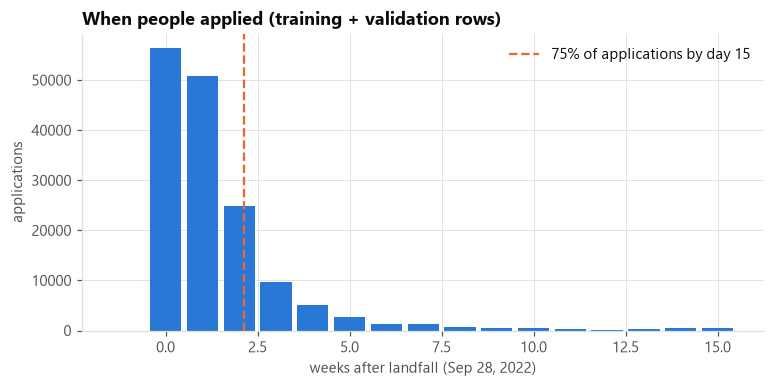

In [15]:
days = tables["application"].loc[dev_idx, "daysSinceLandfall"]
cut_day = days.sort_values(kind="stable").iloc[int(len(days) * 0.75)]
weeks = (days // 7).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(weeks.index, weeks.values, color=BLUE, width=0.85)
ax.axvline(cut_day / 7, color=ORANGE, ls="--", lw=1.5, label=f"75% of applications by day {cut_day:.0f}")
ax.set(xlabel="weeks after landfall (Sep 28, 2022)", ylabel="applications", title="When people applied (training + validation rows)")
ax.legend(frameon=False)
fig.savefig(FIG_DIR / "m2_eval_applications_by_week.png")
plt.show()

---
# Part 5: Leakage Check on `currentLocation` (Section 5.5)

`currentLocation` is the second most important Tier 2 input, but some of its values (for example a FEMA-provided housing unit) only happen *after* aid is given, so part of it may record the answer.
To measure how much Tier 2 depends on it, we refit Tier 2 without that column, on the same training rows, and compare validation AUC.

In [16]:
tier = "inspection"
X_tr, y_tr = DATA[tier]["train"]
X_va, y_va = DATA[tier]["val"]
X_tr_nl, X_va_nl = X_tr.drop(columns="currentLocation"), X_va.drop(columns="currentLocation")
model_nl = Pipeline([
    ("prep", make_preprocessor(X_tr_nl)),
    ("model", HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE,
                                             **BEST_SETTINGS[tier])),
]).fit(X_tr_nl, y_tr)
auc_nl = roc_auc_score(y_va, model_nl.predict_proba(X_va_nl)[:, 1])
LEAK_CHECK = pd.DataFrame({
    "validation AUC": [METRICS.loc[TIER_NAMES[tier], "AUC"], round(auc_nl, 3), METRICS.loc[TIER_NAMES["application"], "AUC"]],
}, index=["Tier 2 with currentLocation", "Tier 2 without currentLocation", "Tier 1 (for comparison)"])
LEAK_CHECK

,validation AUC
Tier 2 with currentLocation,0.939
Tier 2 without currentLocation,0.928
Tier 1 (for comparison),0.883


In [17]:
# Approval rate by currentLocation code, training rows only
loc = raw.loc[SPLIT_INDEX["train"], "currentLocation"].astype(str)
(pd.DataFrame({"code": loc, "eligible": tables[tier].loc[SPLIT_INDEX["train"], TARGET]})
   .groupby("code")["eligible"].agg(applicants="size", share_eligible="mean")
   .sort_values("applicants", ascending=False).round(3))

,applicants,share_eligible
code,,
D,79262,0.467
F,18744,0.696
H,6712,0.289
SR,4312,0.364
R,3259,0.871
RVT,1080,0.806
NH,867,0.385
PRU,682,0.774
C,500,0.606


---
# AI Usage
| Date | Tool | What the AI did | What Anthony did or verified |
|---|---|---|---|
| 2026-11-23 | Claude (Claude Code) | Built this notebook: copied the shared setup cells from the fairness notebook, wrote Parts 2–5 (metrics, permutation importance, temporal check, currentLocation leakage check), and ran it on the Lee County data. | Verified that the information is properly displayed and that numbers match. |
| 2026-11-26 | Claude (Claude Code) | Added the age and income importance printout to Part 3, because Section 5.2 quotes those two numbers. | Re-ran the notebook and confirmed the age and income table appears (Tier 1: age 0.0053, income 0.0048). |